<a href="https://colab.research.google.com/github/saketh-varma06/DL_ASSIGNMENTS/blob/main/DL_ASS_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MNIST Classification Project
This notebook demonstrates downloading, training, and evaluating a PyTorch model on the MNIST dataset.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Define transforms for the training and testing data
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load the training data
train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Download and load the test data
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

print(f"Training set size: {len(train_dataset)}")
print(f"Test set size: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 484kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.0MB/s]

Training set size: 60000
Test set size: 10000


## 2. Model Implementations
We define both a baseline Feedforward Neural Network (FNN) and our primary Convolutional Neural Network (CNN) architecture.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

# Baseline Model: Feedforward Neural Network
class BaselineFNN(nn.Module):
    def __init__(self):
        super(BaselineFNN, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

# Required Architecture: Convolutional Neural Network (CNN)
class MNISTCNN(nn.Module):
    def __init__(self):
        super(MNISTCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(64 * 14 * 14, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = self.dropout1(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout2(x)
        x = self.fc2(x)
        return x

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 3. Training and Evaluation Loops
Here we write general functions to train and evaluate PyTorch models while recording metrics for evaluation.

In [ ]:
import torch.optim as optim
import time

def train_model(model, train_loader, optimizer, criterion, epochs=5):
    model.train()
    epoch_losses = []
    epoch_accs = []

    for epoch in range(1, epochs + 1):
        running_loss = 0.0
        correct = 0
        total = 0
        start_time = time.time()

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = 100.0 * correct / total
        epoch_losses.append(epoch_loss)
        epoch_accs.append(epoch_acc)

        duration = time.time() - start_time
        print(f"Epoch {epoch}/{epochs} - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}% - Time: {duration:.2f}s")

    return epoch_losses, epoch_accs

def evaluate_model(model, test_loader, criterion):
    model.eval()
    test_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    avg_loss = test_loss / len(test_loader.dataset)
    accuracy = 100.0 * correct / total
    print(f"Test Loss: {avg_loss:.4f} - Test Accuracy: {accuracy:.2f}%")
    return avg_loss, accuracy, all_preds, all_targets

## 4. Train Both Models
Now we train both the Baseline FNN and the CNN model for comparison.

In [ ]:
criterion = nn.CrossEntropyLoss()

print("=== Training Baseline FNN ===")
baseline_model = BaselineFNN().to(device)
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)
baseline_losses, baseline_accs = train_model(baseline_model, train_loader, baseline_optimizer, criterion, epochs=5)

print("\n=== Training CNN Model ===")
cnn_model = MNISTCNN().to(device)
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)
cnn_losses, cnn_accs = train_model(cnn_model, train_loader, cnn_optimizer, criterion, epochs=5)

=== Training Baseline FNN ===
Epoch 1/5 - Loss: 0.2677 - Accuracy: 92.14% - Time: 13.14s
Epoch 2/5 - Loss: 0.1150 - Accuracy: 96.53% - Time: 12.84s
Epoch 3/5 - Loss: 0.0808 - Accuracy: 97.50% - Time: 13.18s
Epoch 4/5 - Loss: 0.0634 - Accuracy: 97.95% - Time: 12.68s
Epoch 5/5 - Loss: 0.0509 - Accuracy: 98.30% - Time: 13.67s

=== Training CNN Model ===
Epoch 1/5 - Loss: 0.2018 - Accuracy: 93.88% - Time: 19.35s
Epoch 2/5 - Loss: 0.0846 - Accuracy: 97.50% - Time: 17.42s
Epoch 3/5 - Loss: 0.0632 - Accuracy: 98.06% - Time: 17.98s
Epoch 4/5 - Loss: 0.0497 - Accuracy: 98.47% - Time: 17.33s
Epoch 5/5 - Loss: 0.0432 - Accuracy: 98.66% - Time: 17.35s


## 5. Evaluation, Visualizations & Baseline Comparison
We evaluate both models on the unseen test set, plot their training curves, display visual test predictions, and present our final comparative summary.

=== Evaluating Baseline FNN ===
Test Loss: 0.0800 - Test Accuracy: 97.70%

=== Evaluating CNN Model ===
Test Loss: 0.0278 - Test Accuracy: 99.13%


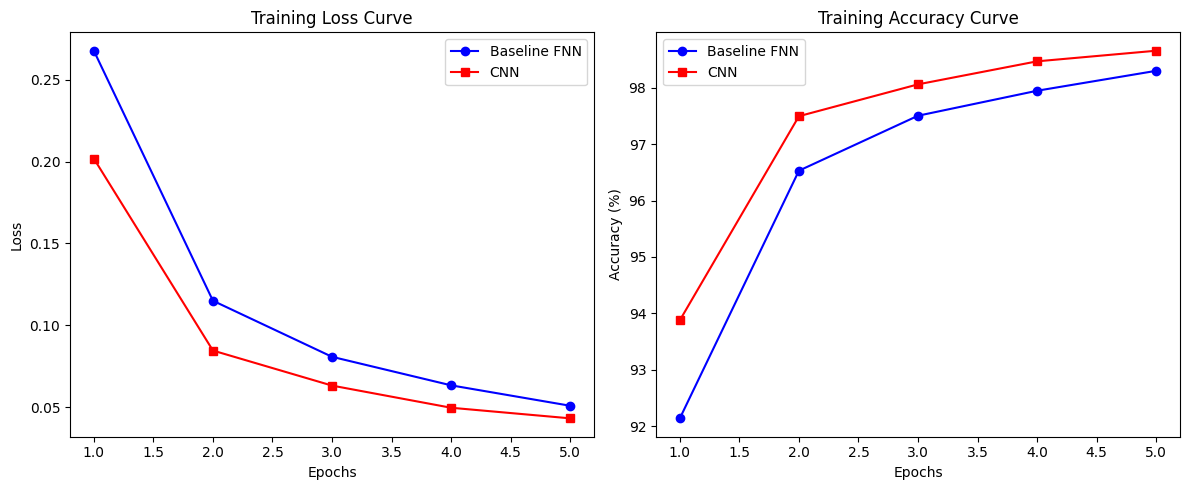

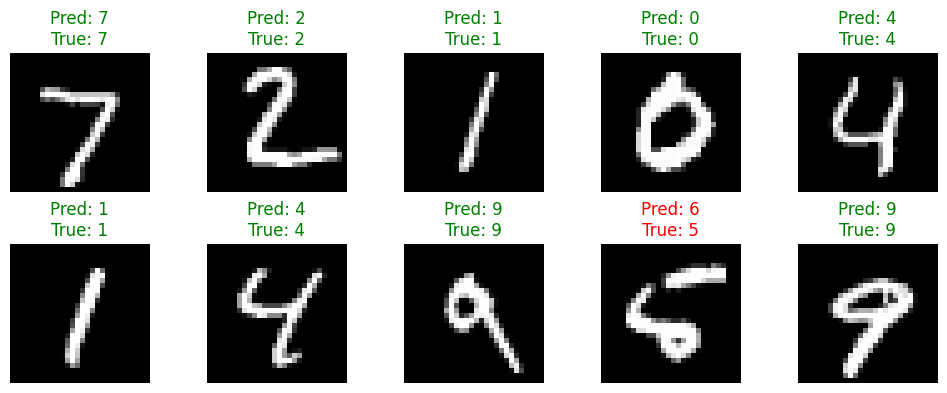


Classification Report for CNN Model:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("=== Evaluating Baseline FNN ===")
bas_loss, bas_acc, bas_preds, bas_targets = evaluate_model(baseline_model, test_loader, criterion)

print("\n=== Evaluating CNN Model ===")
cnn_loss, cnn_acc, cnn_preds, cnn_targets = evaluate_model(cnn_model, test_loader, criterion)

# Plot Loss & Accuracy Curves
epochs = range(1, len(baseline_losses) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, baseline_losses, 'b-o', label='Baseline FNN')
plt.plot(epochs, cnn_losses, 'r-s', label='CNN')
plt.title('Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, baseline_accs, 'b-o', label='Baseline FNN')
plt.plot(epochs, cnn_accs, 'r-s', label='CNN')
plt.title('Training Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

# Visualize CNN predictions
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)
outputs = cnn_model(images)
_, preds = outputs.max(1)

plt.figure(figsize=(10, 4))
for idx in range(10):
    plt.subplot(2, 5, idx + 1)
    plt.imshow(images[idx].cpu().squeeze(), cmap='gray')
    color = 'green' if preds[idx].item() == labels[idx].item() else 'red'
    plt.title(f"Pred: {preds[idx].item()}\nTrue: {labels[idx].item()}", color=color)
    plt.axis('off')
plt.tight_layout()
plt.show()

# Print Detailed Classification Summary
print("\nClassification Report for CNN Model:")
print(classification_report(cnn_targets, cnn_preds))